### EDA
##### Author: Samuel Furneaux
##### Last updated: 14/10/2026

### Exploration of:
#### - heartrate_seconds_merged.csv
#### - minuteMETsNarrow_merged.csv
#### - sleepDay_merged.csv

In [75]:
## Import libraries

import pandas as pd
import seaborn as sns
import numpy as np
from pathlib import Path


In [15]:
data_path = Path.cwd().parent / "datafolder"
files = []
for file in Path(data_path).iterdir():
    if str(file)[-4:] == '.csv':
        files.append(file)

### heartrate_seconds_merged.csv



##### Initial thoughts:
##### - We have heart rates taken from 12 April 2016 - 12 May 2016 -> down to the second.
##### - data is assigned an ID.
##### - BUT, we have no idea what is being done by the person when the heart rate has been taken.

In [ ]:
data_hr = pd.read_csv(files[1])
print(data_hr.head())
print(f"\n Number of rows in data: {len(data_hr)}")
print(f"\n Number of duplicates in data: {data_hr.duplicated().sum()}")
print(f"\n Number of rows with missing values:\n{data_hr.isnull().sum()}")

           Id                  Time  Value
0  2022484408  4/12/2016 7:21:00 AM     97
1  2022484408  4/12/2016 7:21:05 AM    102
2  2022484408  4/12/2016 7:21:10 AM    105
3  2022484408  4/12/2016 7:21:20 AM    103
4  2022484408  4/12/2016 7:21:25 AM    101

 Number of rows in data: 2483658

 Number of duplicates in data: 0

 Number of rows with missing values:
Id       0
Time     0
Value    0
dtype: int64


In [38]:
print(data_hr.info())

data_hr['Time'] = pd.to_datetime(data_hr['Time'], format="%m/%d/%Y %I:%M:%S %p")

<class 'pandas.DataFrame'>
RangeIndex: 2483658 entries, 0 to 2483657
Data columns (total 3 columns):
 #   Column  Dtype         
---  ------  -----         
 0   Id      int64         
 1   Time    datetime64[us]
 2   Value   int64         
dtypes: datetime64[us](1), int64(2)
memory usage: 56.8 MB
None


In [101]:
print(f"{data_hr.Id.nunique()}")
print(f"{data_hr.Id.value_counts()}")

14
Id
4020332650    285461
6962181067    266326
5553957443    255174
4388161847    249748
5577150313    248560
8877689391    228841
4558609924    192168
6117666160    158899
2022484408    154104
2347167796    152683
7007744171    133592
8792009665    122841
6775888955     32771
2026352035      2490
Name: count, dtype: int64


In [53]:
print(f"{data_hr.Time.max()}")
print(f"{data_hr.Time.min()}")
data_hr.Time.dt.normalize().value_counts()


2016-05-12 16:20:00
2016-04-12 00:00:00


Time
2016-04-16    108348
2016-05-03    104863
2016-04-15    104099
2016-04-12     99149
2016-05-04     97258
2016-04-28     88028
2016-04-23     86843
2016-04-27     86514
2016-04-22     86388
2016-05-10     86256
2016-04-20     86234
2016-04-26     85417
2016-05-05     85376
2016-04-14     84339
2016-05-06     84072
2016-04-29     83035
2016-05-08     80693
2016-04-21     79813
2016-04-30     78963
2016-04-19     76696
2016-04-18     73106
2016-04-25     72810
2016-04-13     72525
2016-05-09     72408
2016-05-02     71440
2016-04-24     70664
2016-05-01     68515
2016-04-17     67275
2016-05-07     64240
2016-05-11     56701
2016-05-12     21590
Name: count, dtype: int64

In [93]:
print(data_hr.Time.dt.normalize().sort_values().unique())

<DatetimeArray>
['2016-04-12 00:00:00', '2016-04-13 00:00:00', '2016-04-14 00:00:00',
 '2016-04-15 00:00:00', '2016-04-16 00:00:00', '2016-04-17 00:00:00',
 '2016-04-18 00:00:00', '2016-04-19 00:00:00', '2016-04-20 00:00:00',
 '2016-04-21 00:00:00', '2016-04-22 00:00:00', '2016-04-23 00:00:00',
 '2016-04-24 00:00:00', '2016-04-25 00:00:00', '2016-04-26 00:00:00',
 '2016-04-27 00:00:00', '2016-04-28 00:00:00', '2016-04-29 00:00:00',
 '2016-04-30 00:00:00', '2016-05-01 00:00:00', '2016-05-02 00:00:00',
 '2016-05-03 00:00:00', '2016-05-04 00:00:00', '2016-05-05 00:00:00',
 '2016-05-06 00:00:00', '2016-05-07 00:00:00', '2016-05-08 00:00:00',
 '2016-05-09 00:00:00', '2016-05-10 00:00:00', '2016-05-11 00:00:00',
 '2016-05-12 00:00:00']
Length: 31, dtype: datetime64[us]


count   2483658.0000
mean         77.3284
std          19.4045
min          36.0000
10%          57.0000
25%          63.0000
50%          73.0000
75%          88.0000
90%         102.0000
99%         148.0000
max         203.0000
Name: Value, dtype: float64


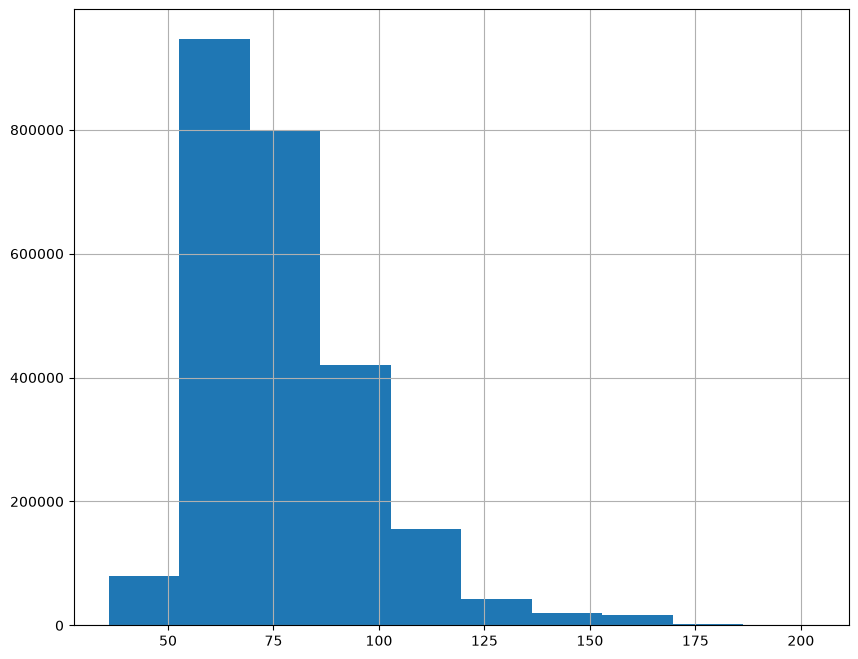

In [72]:
pd.set_option("display.float_format", "{:.4f}".format)
data_hr.Value.hist(figsize=(10,8))
print(data_hr.Value.describe([.1, .25, .5, .75, .9, .99]))

<Axes: xlabel='Time', ylabel='Value'>

/Users/samfurneaux/Documents/University/DATA2007/DATA2007-Fitbit-Dashboard-Group/data2007/lib/python3.13/site-packages/IPython/core/events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/Users/samfurneaux/Documents/University/DATA2007/DATA2007-Fitbit-Dashboard-Group/data2007/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


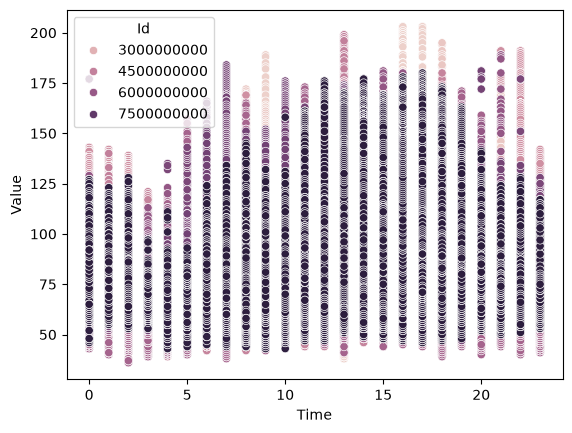

In [85]:
sns.scatterplot(x = data_hr.Time.dt.hour, y=data_hr.Value, hue = data_hr.Id)

### sleepDay_merged.csv


In [97]:
data_sleep = pd.read_csv(files[0])
print(data_sleep.head())
print(f"\n Number of rows in data: {len(data_sleep)}")
print(f"\n Number of duplicates in data: {data_sleep.duplicated().sum()}")
print(f"\n Number of rows with missing values:\n{data_sleep.isnull().sum()}")

           Id               SleepDay  TotalSleepRecords  TotalMinutesAsleep  \
0  1503960366  4/12/2016 12:00:00 AM                  1                 327   
1  1503960366  4/13/2016 12:00:00 AM                  2                 384   
2  1503960366  4/15/2016 12:00:00 AM                  1                 412   
3  1503960366  4/16/2016 12:00:00 AM                  2                 340   
4  1503960366  4/17/2016 12:00:00 AM                  1                 700   

   TotalTimeInBed  
0             346  
1             407  
2             442  
3             367  
4             712  

 Number of rows in data: 413

 Number of duplicates in data: 3

 Number of rows with missing values:
Id                    0
SleepDay              0
TotalSleepRecords     0
TotalMinutesAsleep    0
TotalTimeInBed        0
dtype: int64


In [99]:
print(data_sleep.info())

data_sleep['SleepDay'] = pd.to_datetime(data_sleep['SleepDay'], format="%m/%d/%Y %I:%M:%S %p")

<class 'pandas.DataFrame'>
RangeIndex: 413 entries, 0 to 412
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Id                  413 non-null    int64
 1   SleepDay            413 non-null    str  
 2   TotalSleepRecords   413 non-null    int64
 3   TotalMinutesAsleep  413 non-null    int64
 4   TotalTimeInBed      413 non-null    int64
dtypes: int64(4), str(1)
memory usage: 16.3 KB
None


In [103]:
print(f"{data_sleep['SleepDay'].max()}")
print(f"{data_sleep['SleepDay'].min()}")
data_sleep['SleepDay'].dt.normalize().value_counts()


2016-05-12 00:00:00
2016-04-12 00:00:00


SleepDay
2016-04-15    17
2016-04-28    16
2016-05-01    16
2016-04-20    15
2016-04-21    15
2016-04-23    15
2016-04-29    15
2016-04-30    15
2016-04-13    14
2016-04-16    14
2016-04-19    14
2016-04-26    14
2016-05-07    14
2016-05-08    14
2016-04-27    14
2016-04-12    13
2016-04-24    13
2016-04-25    13
2016-05-02    13
2016-05-05    13
2016-04-14    13
2016-04-22    13
2016-04-17    12
2016-05-03    12
2016-05-06    12
2016-05-10    12
2016-05-04    12
2016-05-09    11
2016-05-11    11
2016-04-18    10
2016-05-12     8
Name: count, dtype: int64

In [105]:
print(data_sleep['SleepDay'].dt.normalize().sort_values().unique())

<DatetimeArray>
['2016-04-12 00:00:00', '2016-04-13 00:00:00', '2016-04-14 00:00:00',
 '2016-04-15 00:00:00', '2016-04-16 00:00:00', '2016-04-17 00:00:00',
 '2016-04-18 00:00:00', '2016-04-19 00:00:00', '2016-04-20 00:00:00',
 '2016-04-21 00:00:00', '2016-04-22 00:00:00', '2016-04-23 00:00:00',
 '2016-04-24 00:00:00', '2016-04-25 00:00:00', '2016-04-26 00:00:00',
 '2016-04-27 00:00:00', '2016-04-28 00:00:00', '2016-04-29 00:00:00',
 '2016-04-30 00:00:00', '2016-05-01 00:00:00', '2016-05-02 00:00:00',
 '2016-05-03 00:00:00', '2016-05-04 00:00:00', '2016-05-05 00:00:00',
 '2016-05-06 00:00:00', '2016-05-07 00:00:00', '2016-05-08 00:00:00',
 '2016-05-09 00:00:00', '2016-05-10 00:00:00', '2016-05-11 00:00:00',
 '2016-05-12 00:00:00']
Length: 31, dtype: datetime64[us]


In [106]:
print(f"{data_hr.Id.nunique()}")
print(f"{data_hr.Id.value_counts()}")

14
Id
4020332650    285461
6962181067    266326
5553957443    255174
4388161847    249748
5577150313    248560
8877689391    228841
4558609924    192168
6117666160    158899
2022484408    154104
2347167796    152683
7007744171    133592
8792009665    122841
6775888955     32771
2026352035      2490
Name: count, dtype: int64


In [ ]:
### match to other data set?

hr_ids = set(data_hr.Id)
sleep_ids = set(data_sleep.Id)
set.intersection(hr_ids,sleep_ids)
set.difference(hr_ids,sleep_ids)

{2022484408, 8877689391}

In [117]:
data_sleep[['TotalSleepRecords','TotalMinutesAsleep','TotalTimeInBed']].describe([.1, .25, .5, .75, .9, .99])

,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
count,413.0000,413.0000,413.0000
mean,1.1186,419.4673,458.6392
std,0.3455,118.3447,127.1016
min,1.0000,58.0000,61.0000
10%,1.0000,283.4000,338.8000
25%,1.0000,361.0000,403.0000
50%,1.0000,433.0000,463.0000
75%,1.0000,490.0000,526.0000
90%,2.0000,534.6000,568.0000
99%,2.0000,699.0400,834.8400


<Axes: xlabel='TotalTimeInBed', ylabel='TotalMinutesAsleep'>

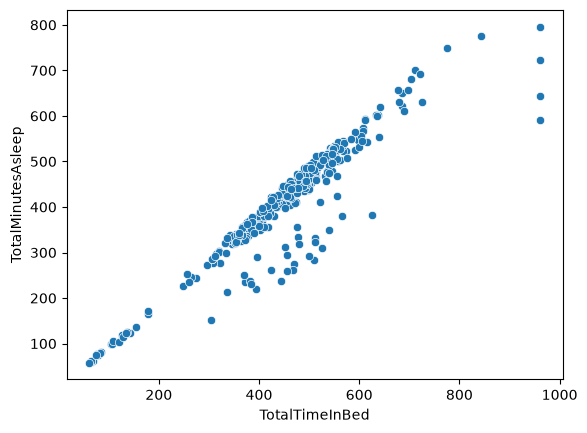

In [120]:
sns.scatterplot(x=data_sleep.TotalTimeInBed,y=data_sleep.TotalMinutesAsleep)

In [121]:
max(data_sleep.TotalMinutesAsleep/data_sleep.TotalTimeInBed)

1.0

### minuteMETsNarrow_merged.csv

metabolic equivalent of task (MET) definitions for Fitbit PA summary variables are: <1.5 METs, sedentary minutes; 1.5–3.0 METs, lightly active minutes; 3.0–6.0 METS, fairly (or moderately) active minutes; >6.0 METs, very (or vigorously) active minutes.


In [123]:
data_METs = pd.read_csv(files[2])
print(data_METs.head())
print(f"\n Number of rows in data: {len(data_METs)}")
print(f"\n Number of duplicates in data: {data_METs.duplicated().sum()}")
print(f"\n Number of rows with missing values:\n{data_METs.isnull().sum()}")

           Id         ActivityMinute  METs
0  1503960366  4/12/2016 12:00:00 AM    10
1  1503960366  4/12/2016 12:01:00 AM    10
2  1503960366  4/12/2016 12:02:00 AM    10
3  1503960366  4/12/2016 12:03:00 AM    10
4  1503960366  4/12/2016 12:04:00 AM    10

 Number of rows in data: 1325580

 Number of duplicates in data: 0

 Number of rows with missing values:
Id                0
ActivityMinute    0
METs              0
dtype: int64


In [127]:
print(data_METs.info())

data_METs['ActivityMinute'] = pd.to_datetime(data_METs['ActivityMinute'], format="%m/%d/%Y %I:%M:%S %p")

<class 'pandas.DataFrame'>
RangeIndex: 1325580 entries, 0 to 1325579
Data columns (total 4 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   Id              1325580 non-null  int64         
 1   ActivityMinute  1325580 non-null  str           
 2   METs            1325580 non-null  int64         
 3   SleepDay        1325580 non-null  datetime64[us]
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 40.5 MB
None


In [128]:
print(f"{data_METs['ActivityMinute'].max()}")
print(f"{data_METs['ActivityMinute'].min()}")
data_METs['ActivityMinute'].dt.normalize().value_counts()



2016-05-12 15:59:00
2016-04-12 00:00:00


ActivityMinute
2016-04-12    47520
2016-04-13    47520
2016-04-14    47520
2016-04-15    47040
2016-04-16    46080
2016-04-17    46080
2016-04-18    46080
2016-04-19    46080
2016-04-20    46080
2016-04-21    46080
2016-04-22    46080
2016-04-23    46080
2016-04-24    46080
2016-04-25    46080
2016-04-26    46080
2016-04-27    46080
2016-04-28    46080
2016-04-29    44940
2016-04-30    43200
2016-05-01    42720
2016-05-02    41760
2016-05-03    41760
2016-05-04    41760
2016-05-05    41760
2016-05-06    41760
2016-05-07    39540
2016-05-08    38880
2016-05-09    37740
2016-05-10    34560
2016-05-11    31380
2016-05-12    15180
Name: count, dtype: int64

In [138]:
data_METs.METs.describe()
data_METs.METs.nunique()
print(data_METs.METs.value_counts(sort=True))

METs
10     879413
11     120167
12      75145
26      36087
13      31225
        ...  
149         1
157         1
153         1
21          1
25          1
Name: count, Length: 136, dtype: int64


In [141]:
### match to other data set?

hr_ids = set(data_hr.Id)
sleep_ids = set(data_sleep.Id)
mets_ids = set(data_METs.Id)

#set.intersection(hr_ids,sleep_ids,mets_ids)
set.difference(hr_ids,sleep_ids,mets_ids)

set()